# Week 03 - epdlxj wjscjfl
## 3-1. 데이터 다루기

Numpy를 이용하여 데이터를 구성하고,
훈련데이터와 테스트 데이터르 나눈다

특성마다 데이터의 크기 차이가 있을 때 발생하는 문제를 확인하고,
표준점수를 이용하여 데이터의 스케일을 맞춘다

In [2]:
# 도미 35마리와 빙어 14마리의 길이 데이터
fish_length = [
    25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7,
    30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0,
    32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0,
    34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0,
    36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0,
    9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8,
    11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0
]

# 도미 35마리와 빙어 14마리의 무게 데이터
fish_weight = [
    242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0,
    390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0,
    600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0,
    685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0,
    850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0,
    6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0,
    9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9
]

In [4]:
import numpy as np
np.column_stack(([1,2,3], [4,5,6]))

array([[1, 4],
       [2, 5],
       [3, 6]])

In [6]:
np.vstack(([1,2,3], [4,5,6]))

array([[1, 2, 3],
       [4, 5, 6]])

In [7]:
np.ones(5)

array([1., 1., 1., 1., 1.])

In [8]:
np.zeros(5)

array([0., 0., 0., 0., 0.])

In [9]:
np.full((2, 3), 9)

array([[9, 9, 9],
       [9, 9, 9]])

In [10]:
np.concatenate((np.ones(5), np.zeros(5)))

array([1., 1., 1., 1., 1., 0., 0., 0., 0., 0.])

In [11]:
# fish_data = [[l, w] for l, w in zip(length, weight)]
# 길이와 무게를 열 방향으로 합친다.

fish_data = np.column_stack((fish_length, fish_weight))

print(fish_data[:5])

[[ 25.4 242. ]
 [ 26.3 290. ]
 [ 26.5 340. ]
 [ 29.  363. ]
 [ 29.  430. ]]


In [12]:
# 도미 35마리는 1, 빙어 14마리는 0

fish_target = np.concatenate(
    (np.ones(35), np.zeros(14))
)

print(fish_target)

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0.]


In [ ]:
from sklearn.model_selection import train_test_split
train_input, test_input, train_target, test_target = train_test_split(
    fish_data,
    fish_target,
    random_state=42
)
print(train_input.shape, test_input.shape)
print(train_target.shape, test_target.shape)
print(test_target)

# 2주차 : 인덱스 생성 - shuffle -> 앞 35개, 뒤 14개
# 3주차 train_testa-split() -> 알아서 썩고 -> 알아서 훈련/테스트 데이터로 나눠줌

(36, 2) (13, 2)
(36,) (13,)
[1. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [14]:
train_input, test_input, train_target, test_target = train_test_split(
    fish_data,
    fish_target,
    stratify=fish_target, #원래 타깃의 비율을 고려해서 훈련/테스트 데이터를 나누도록 하는 옵션
    random_state=42
)

In [15]:
# 모델 학습
from sklearn.neighbors import KNeighborsClassifier

kn = KNeighborsClassifier()

kn.fit(train_input, train_target)

print(kn.score(test_input, test_target))

1.0


In [16]:
print(kn.predict([[25, 150]]))  #길이 25, 무게 150

[0.]


In [18]:
distances, indexes = kn.kneighbors([[25, 150]])

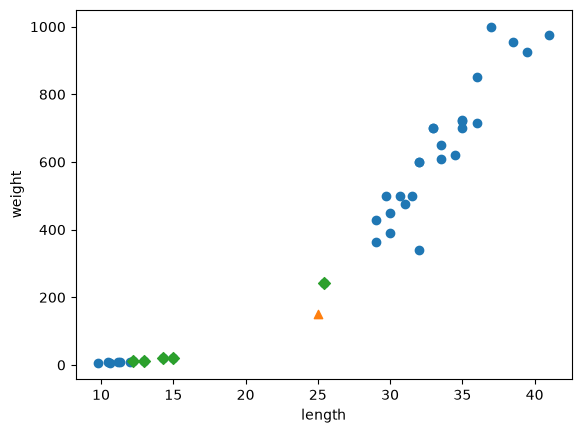

In [19]:
import matplotlib.pyplot as plt

plt.scatter(train_input[:, 0], train_input[:, 1])

# 새 생선
plt.scatter(25, 150, marker='^')

# 가장 가까운 이웃들
plt.scatter(
    train_input[indexes, 0],
    train_input[indexes, 1],
    marker='D'
)

plt.xlabel('length')
plt.ylabel('weight')
plt.show()

길이와 무게의 스케일이 다르기때문에 생긴느 문제
길이는 10-40정도, 무게는 10-1000 정도 차이가 남 사람이 보기에는 도미가 가까워도 수치상으론느 빙어가 가까운 거
=> 표준 편차를 이용

In [ ]:
# 흔련 데이터의 평균을 구한다
mean = np.mean(train_input, axis=0)
std = np.std(train_input, axis=0)
print(mean, std)

[ 27.29722222 454.09722222] [  9.98244253 323.29893931]


In [22]:
# 표준점수 구하기 [ 공식 : (데이터 - 평균) / 표준편차 ]
train_scaled = (train_input - mean) / std
# 얼마나 떨어져 있느냐가 아니라 표준에서 얼마나 떨어져 있냐로 바꾼 것

In [26]:
# [25,150]도 같은 방식으로 바꾸기
new = ([25, 150] - mean) / std
print(new)

[-0.23012627 -0.94060693]


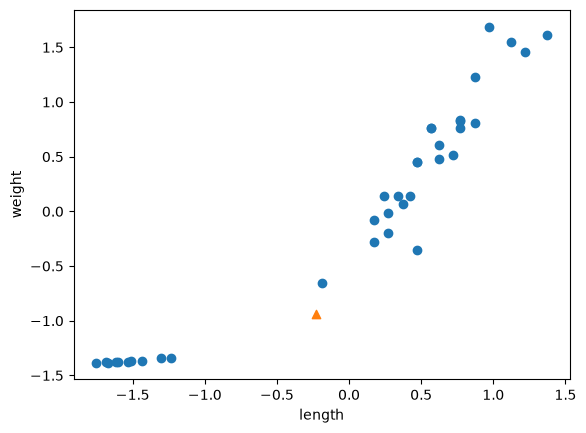

In [27]:
plt.scatter(train_scaled[:, 0], train_scaled[:, 1])
plt.scatter(new[0], new[1], marker='^')

plt.xlabel('length')
plt.ylabel('weight')
plt.show()

In [28]:
kn.fit(train_scaled, train_target)
test_scaled = (test_input - mean) / std
print(kn.score(test_scaled, test_target))


1.0


In [29]:
print(kn.predict([new]))

[1.]


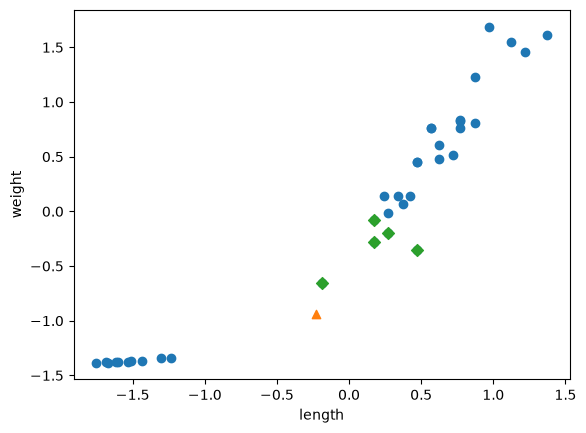

In [30]:
distances, indexes = kn.kneighbors([new])

plt.scatter(train_scaled[:, 0], train_scaled[:, 1])
plt.scatter(new[0], new[1], marker='^')

plt.scatter(
    train_scaled[indexes, 0],
    train_scaled[indexes, 1],
    marker='D'
)

plt.xlabel('length')
plt.ylabel('weight')
plt.show()

## 3-1 실습 정리

- NumPy의 `column_stack()`을 이용하여 길이와 무게 데이터를 하나의 배열로 만들었다.
- `ones()`, `zeros()`, `concatenate()`를 이용하여 타깃 데이터를 만들었다.
- `train_test_split()`을 이용하여 훈련 데이터와 테스트 데이터를 나누었다.
- `stratify`를 이용하면 타깃의 비율을 고려하여 데이터를 나눌 수 있다.
- k-최근접 이웃은 데이터 사이의 거리를 이용하여 분류한다.
- 길이와 무게처럼 특성의 스케일이 다르면 거리 계산에 영향을 줄 수 있다.
- 평균과 표준편차를 이용한 표준점수로 데이터의 스케일을 맞출 수 있다.
- 훈련 데이터와 테스트 데이터는 동일한 기준으로 전처리해야 한다.